In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
df = pd.read_csv("test.csv")


In [6]:
print("\nTypes des colonnes :\n", df.dtypes)


Types des colonnes :
 Unnamed: 0                             int64
id                                     int64
Gender                                   str
Customer Type                            str
Age                                    int64
Type of Travel                           str
Class                                    str
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness                     

In [7]:
print("Taille (lignes, colonnes) :", df.shape)

Taille (lignes, colonnes) : (25976, 25)


In [8]:
print("\nColonnes avec des cases vides :\n", df.isna().sum()[lambda s: s > 0])#[lambda s: s > 0] filtrage par fonction



Colonnes avec des cases vides :
 Arrival Delay in Minutes    83
dtype: int64


In [9]:
print("\nRépartition de la satisfaction :\n",df["satisfaction"].value_counts(normalize=True).round(3))



Répartition de la satisfaction :
 satisfaction
neutral or dissatisfied    0.561
satisfied                  0.439
Name: proportion, dtype: float64


In [10]:
df = df.drop(columns=["Unnamed: 0", "id"], errors="ignore")#supprimer les colonnes vide , errors="ignore" ca veut dire ignore les colonnes vides sans plantage 

df["sat"] = (df["satisfaction"] == "satisfied").astype(int) #convertire la colonne de type str vers int 

df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Departure Delay in Minutes"])# la focntion .fillna() sert a remplir la colonne de gouche par la colonne a droit sur le meme ligne 

In [11]:
sc = ["Inflight wifi service", "Departure/Arrival time convenient",
      "Ease of Online booking", "Gate location", "Food and drink",
      "Online boarding", "Seat comfort", "Inflight entertainment",
      "On-board service", "Leg room service", "Baggage handling",
      "Checkin service", "Inflight service", "Cleanliness"]


In [12]:
print("\nPart de '0' (non concerné) par service :\n",
      (df[sc] == 0).mean().round(3))


Part de '0' (non concerné) par service :
 Inflight wifi service                0.031
Departure/Arrival time convenient    0.053
Ease of Online booking               0.046
Gate location                        0.000
Food and drink                       0.001
Online boarding                      0.025
Seat comfort                         0.000
Inflight entertainment               0.000
On-board service                     0.000
Leg room service                     0.005
Baggage handling                     0.000
Checkin service                      0.000
Inflight service                     0.000
Cleanliness                          0.000
dtype: float64


In [13]:
corr = (
    df[sc].replace(0, np.nan)  #replacer les cases contienne valeur 0 par erreur      
          .assign(sat=df["sat"])  # ajouter la colonne des notes global   
          .corr(method="spearman") #calculer les note des colonnes et normaliser entre -1 et 1 
          ["sat"].drop("sat") #suprimer la colonne de sat pour obtenir jsut les notes des colonnes 
          .sort_values(ascending=False)# rendre dnas l'ordre descroissent
)

In [14]:
print("\nLien de chaque service avec la satisfaction :\n", corr.round(3))



Lien de chaque service avec la satisfaction :
 Online boarding                      0.589
Inflight entertainment               0.401
Inflight wifi service                0.372
Seat comfort                         0.359
On-board service                     0.329
Leg room service                     0.314
Cleanliness                          0.313
Baggage handling                     0.276
Inflight service                     0.266
Checkin service                      0.237
Ease of Online booking               0.223
Food and drink                       0.213
Gate location                       -0.017
Departure/Arrival time convenient   -0.056
Name: sat, dtype: float64


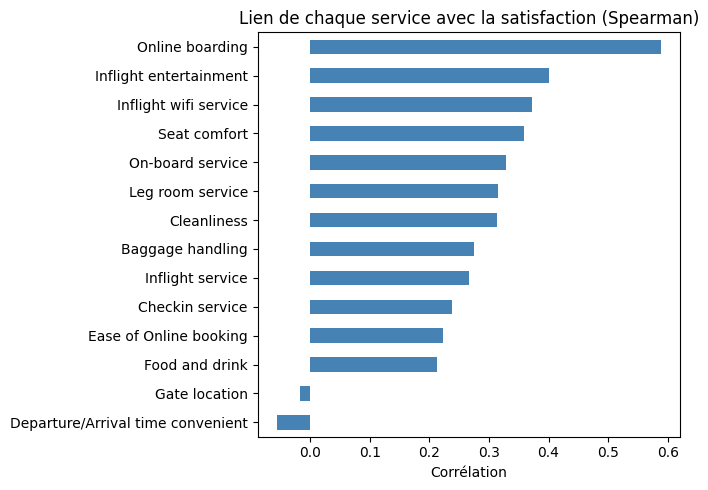

In [15]:
corr.sort_values().plot.barh(figsize=(7, 5), color="steelblue")
plt.title("Lien de chaque service avec la satisfaction (Spearman)")
plt.xlabel("Corrélation")
plt.tight_layout()
plt.show()

In [16]:
par_classe = pd.crosstab(df["Class"], df["sat"], normalize="index").round(3) * 100 # regarde chaque class sont pourcentage de satisfication 
print("\n% de pas satisfaits (0) / satisfaits (1) par classe :\n", par_classe)


% de pas satisfaits (0) / satisfaits (1) par classe :
 sat          0     1
Class               
Business  30.5  69.5
Eco       80.6  19.4
Eco Plus  75.2  24.8


In [17]:
p = chi2_contingency(pd.crosstab(df["Class"], df["sat"]))[1]# on calcule est ce qu'il y a une association entre les deux colonnes
print("\nKhi-deux, p-value :", p) #si p_values <0.05 ca veut dire les satisfications des clients sont associe a les class 


Khi-deux, p-value : 0.0


In [18]:
pr_voyage_class= pd.crosstab([df["Type of Travel"],df["Class"]],df["sat"], normalize="index").round(3) * 100
print(" % par type de voyage et class de voyage \n",pr_voyage_class)

 % par type de voyage et class de voyage 
 sat                          0     1
Type of Travel  Class               
Business travel Business  27.9  72.1
                Eco       68.7  31.3
                Eco Plus  61.0  39.0
Personal Travel Business  90.5   9.5
                Eco       89.8  10.2
                Eco Plus  91.2   8.8


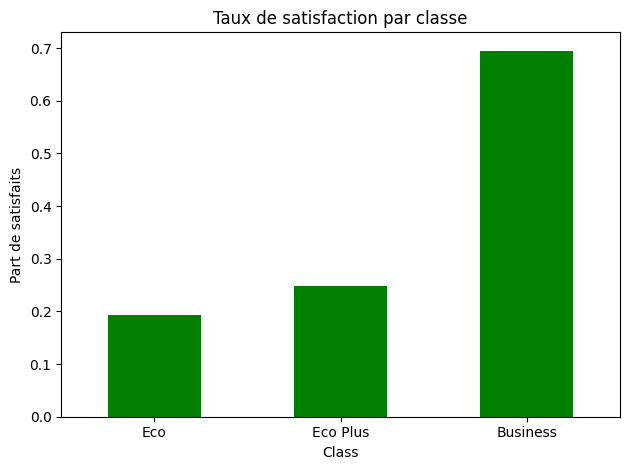

In [19]:
df.groupby("Class")["sat"].mean().sort_values().plot.bar(color="green") # tracage d'un graphe contiene chaque class avec la moyenne des clients satisfait
plt.title("Taux de satisfaction par classe")
plt.ylabel("Part de satisfaits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
cor_retard_sat =df[["Departure Delay in Minutes",
                     "Arrival Delay in Minutes", "sat"]].corr(method = 'spearman')['sat'].round(3)
print('correlation retard /satisfaction',cor_retard_sat)


correlation retard /satisfaction Departure Delay in Minutes   -0.073
Arrival Delay in Minutes     -0.100
sat                           1.000
Name: sat, dtype: float64


In [21]:
tranche = pd.cut(df["Arrival Delay in Minutes"],bins=[-1,0,15,60,120,np.inf],
                 labels=["a l'heure", "1-15 min", "16-60 min", "1-2 h", "> 2 h"])
par_tranche=df.groupby(tranche,observed = True)['sat'].agg(['mean','count']).round(3)
print('satisfaction par tranche de retard : ',par_tranche)

satisfaction par tranche de retard :                             mean  count
Arrival Delay in Minutes              
a l'heure                 0.479  14625
1-15 min                  0.407   5395
16-60 min                 0.377   4177
1-2 h                     0.358   1197
> 2 h                     0.342    582


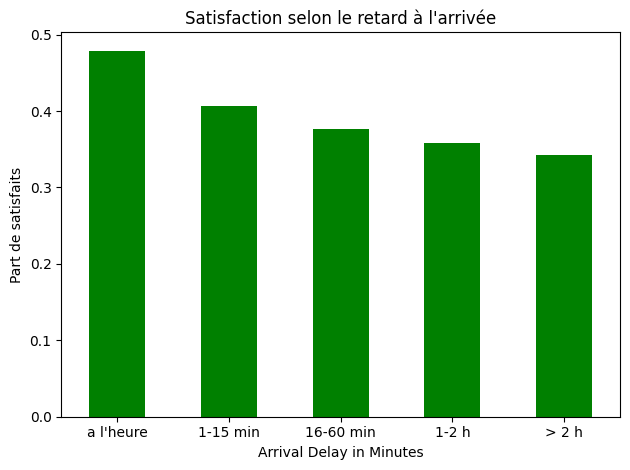

In [22]:
par_tranche["mean"].plot.bar(color="green")
plt.title("Satisfaction selon le retard à l'arrivée")
plt.ylabel("Part de satisfaits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
print("satisfaction par class et ratard : ")
for classe,g in df.groupby("Class"):
    t = pd.cut(g["Arrival Delay in Minutes"],[-1, 0, 60, np.inf],["à l'heure", "<= 1 h", "> 1 h"])
    print(classe,g.groupby(t,observed=True)["sat"].mean().round(3).to_dict())

satisfaction par class et ratard : 
Business {Interval(-1.0, 0.0, closed='right'): 0.734, Interval(0.0, 60.0, closed='right'): 0.651, Interval(60.0, inf, closed='right'): 0.6}
Eco {Interval(-1.0, 0.0, closed='right'): 0.227, Interval(0.0, 60.0, closed='right'): 0.155, Interval(60.0, inf, closed='right'): 0.136}
Eco Plus {Interval(-1.0, 0.0, closed='right'): 0.304, Interval(0.0, 60.0, closed='right'): 0.182, Interval(60.0, inf, closed='right'): 0.181}


In [24]:
print("\nSatisfaction selon le type de client :\n",
      df.groupby("Customer Type")["sat"].mean().round(3))


Satisfaction selon le type de client :
 Customer Type
Loyal Customer       0.481
disloyal Customer    0.252
Name: sat, dtype: float64
